# Stock-Market-ML-Predictor: 03. Exploratory Data Analysis (TRAIN Split Only)
> [!IMPORTANT]
> **Strict Training Isolation (Anti-Leakage Policy):**
> In accordance with honest validation rules, **every single cell, statistic, distribution, and plot in this notebook is computed strictly on the Training split** (`2023-11-01 00:00:00 UTC` to `2025-12-07 04:40:00 UTC`).
> Neither the Validation split nor the locked Test split is loaded, inspected, or used to inform any decision here.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Setup path to import src modules cleanly from any working directory
current_path = Path.cwd().resolve()
for p in [current_path, current_path / 'ML', current_path.parent]:
    if (p / 'src').exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

from src import config
from src.splitting import get_train_data
from src.labels import create_forward_labels, compute_dead_zone_sensitivity, compute_label_balance_report
from src.plotting import (
    plot_train_price_with_ma,
    plot_return_distributions,
    plot_volatility_and_acf,
    plot_time_patterns,
    plot_microstructure_relationships,
    plot_correlation_heatmap,
    plot_regimes_monthly,
    plot_forward_return_horizons,
    plot_label_balance_bars,
)

# Load clean dataset and extract TRAIN split exclusively
df_clean = pd.read_parquet(config.CLEAN_DATA_PATH)
df_train = get_train_data(df_clean)
print('Loaded TRAIN split successfully!')

Loaded TRAIN split successfully!


In [2]:
# 1. Header: Training Partition Metadata
t_start = df_train.index.min()
t_end = df_train.index.max()
n_candles = len(df_train)
n_days = (t_end - t_start).total_seconds() / 86400.0

train_meta = pd.DataFrame({
    'Property': ['Start Timestamp (UTC)', 'End Timestamp (UTC)', 'Candle Count', 'Duration (Days)', 'Share of Dataset (%)'],
    'Value': [str(t_start), str(t_end), f'{n_candles:,}', f'{n_days:.2f} days', f'{(n_candles / len(df_clean))*100:.2f}%']
})
display(train_meta)

,Property,Value
0,Start Timestamp (UTC),2023-11-01 00:00:00+00:00
1,End Timestamp (UTC),2025-12-07 04:40:00+00:00
2,Candle Count,"220,953"
3,Duration (Days),767.19 days
4,Share of Dataset (%),69.43%


In [3]:
# 2. Comprehensive Summary Statistics Table
# Compute required core series
ret_5m = np.log(df_train['close'] / df_train['close'].shift(1))
abs_ret_5m = ret_5m.abs()
labels_12 = create_forward_labels(df_train, horizon=12, dead_zone=config.LABEL_DEAD_ZONE)
fwd_ret_12 = labels_12['forward_return']
vol = df_train['volume']
trades = df_train['number_of_trades']
taker_ratio = (df_train['taker_buy_base_volume'] / df_train['volume'].replace(0, np.nan))
hl_spread = (df_train['high'] - df_train['low']) / df_train['close']

variables = {
    '5m Log Returns': ret_5m,
    '5m Absolute Returns': abs_ret_5m,
    '12-Candle (1h) Forward Returns': fwd_ret_12,
    'Volume (BTC)': vol,
    'Number of Trades': trades,
    'Taker Buy Ratio': taker_ratio,
    '(High - Low) / Close': hl_spread,
}

stat_rows = []
for name, s in variables.items():
    clean_s = s.dropna()
    stat_rows.append({
        'Variable': name,
        'Count': f'{len(clean_s):,}',
        'Mean': clean_s.mean(),
        'Std': clean_s.std(),
        'Median': clean_s.median(),
        'Min': clean_s.min(),
        '1%': clean_s.quantile(0.01),
        '5%': clean_s.quantile(0.05),
        '95%': clean_s.quantile(0.95),
        '99%': clean_s.quantile(0.99),
        'Max': clean_s.max(),
        'Skewness': clean_s.skew(),
        'Kurtosis': clean_s.kurtosis(),
    })

stat_df = pd.DataFrame(stat_rows)
display(stat_df.set_index('Variable'))

,Count,Mean,Std,Median,Min,1%,5%,95%,99%,Max,Skewness,Kurtosis
Variable,,,,,,,,,,,,
5m Log Returns,"220,952",0.000004,0.001528,0.000000,-7.621343e-02,-0.004221,-0.002163,0.002161,0.004232,0.040005,-0.868047,58.667186
5m Absolute Returns,"220,952",0.000979,0.001173,0.000650,0.000000e+00,0.000005,0.000053,0.002975,0.005325,0.076213,6.222793,149.061425
12-Candle (1h) Forward Returns,"220,941",0.000065,0.005132,0.000059,-1.095873e-01,-0.015172,-0.007280,0.007395,0.015063,0.088853,-0.234876,14.787897
Volume (BTC),"220,953",102.008223,144.028695,60.773970,9.095800e-01,7.572440,13.700984,317.026988,667.113918,5471.439430,7.094659,102.258865
Number of Trades,"220,953",10661.642087,12179.474493,6633.000000,4.080000e+02,1293.000000,1911.000000,33374.200000,59059.960000,711259.000000,5.151330,104.788469
Taker Buy Ratio,"220,953",0.484509,0.145247,0.484736,1.427569e-02,0.152391,0.242960,0.725331,0.820266,0.982533,0.012428,-0.175412
(High - Low) / Close,"220,953",0.001778,0.001662,0.001355,8.174756e-08,0.000136,0.000343,0.004563,0.007708,0.083779,6.122366,125.304198


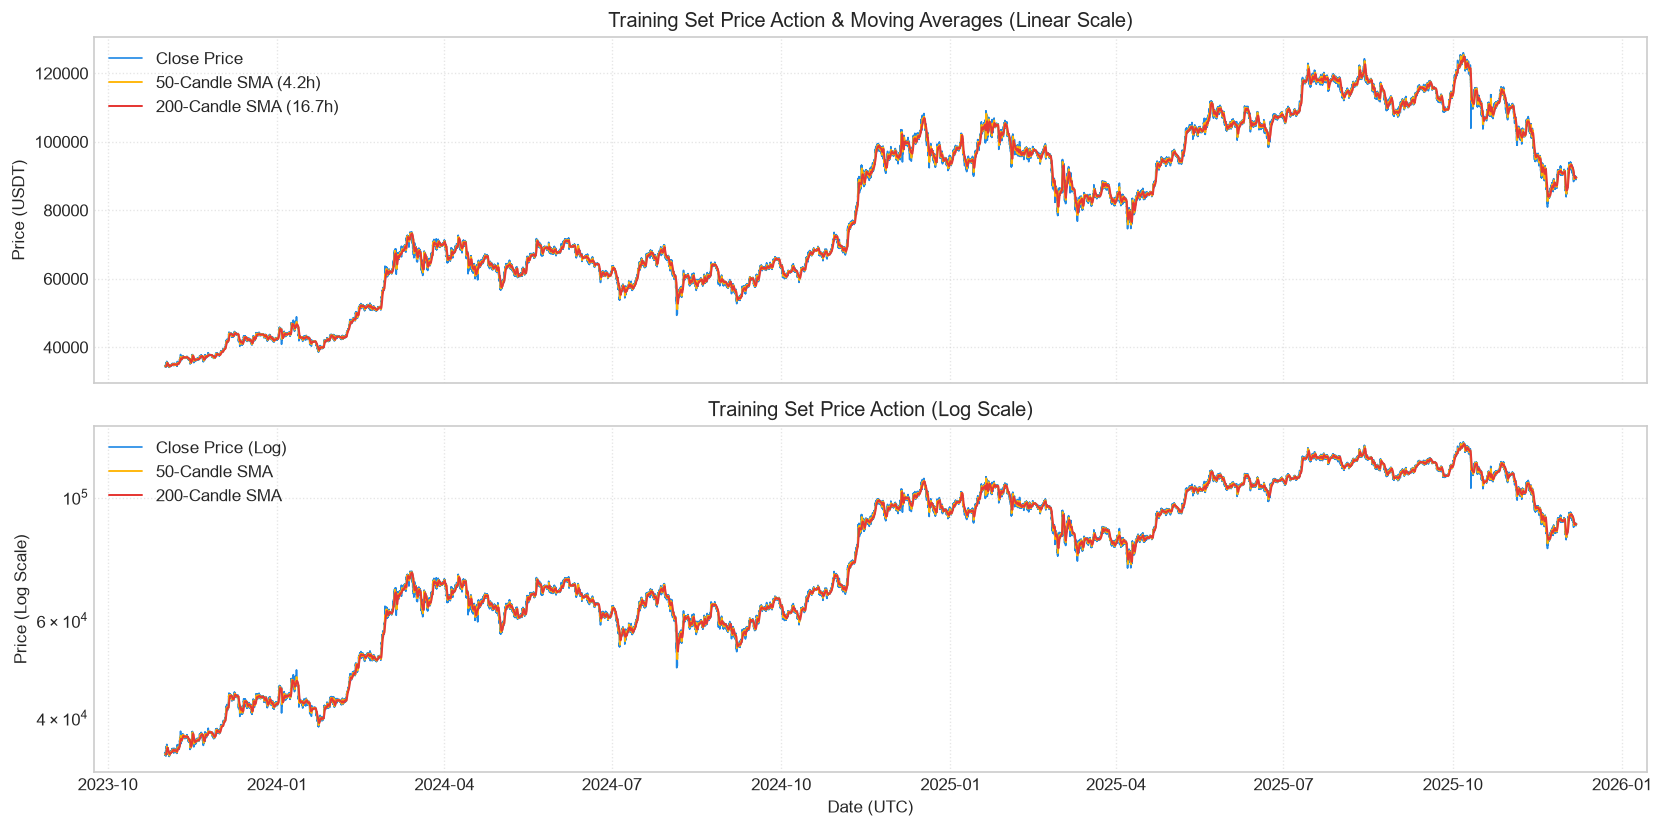

In [4]:
# 3. Training Set Price Action & Moving Averages (Linear & Log Scale)
fig_ma = plot_train_price_with_ma(
    df_train,
    save_path=config.FIGURES_DIR / '01_train_price_moving_averages.png'
)
plt.show()

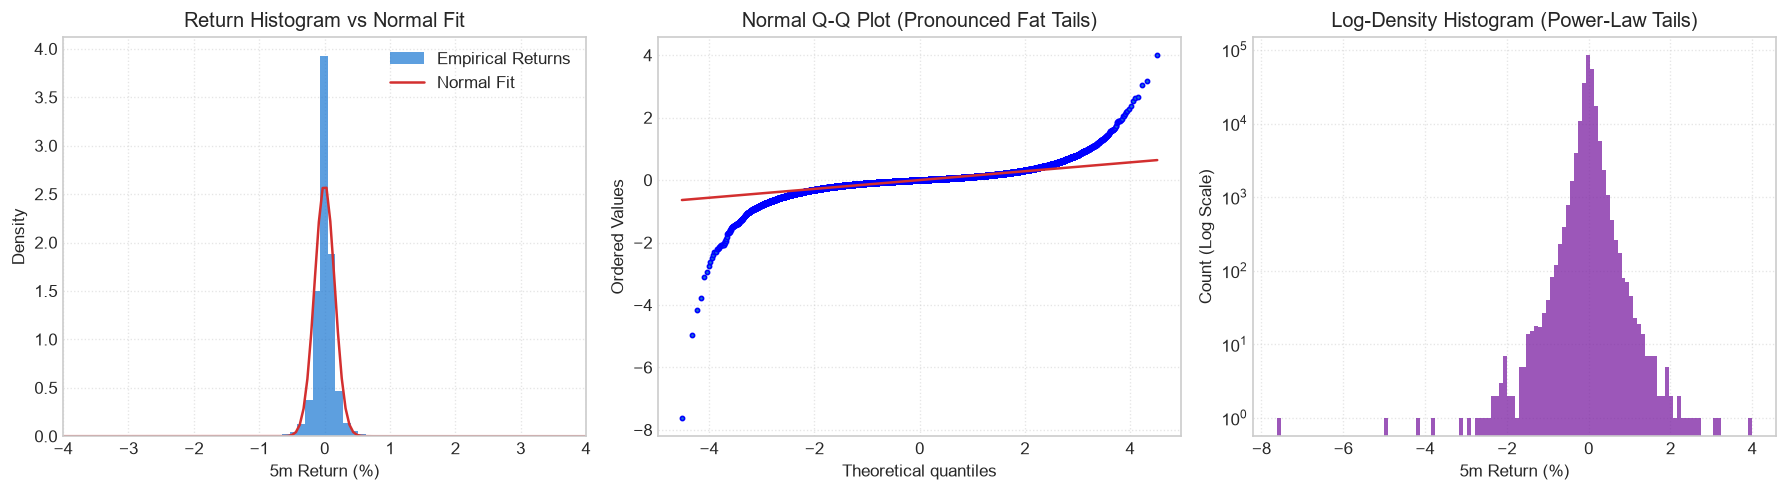

In [5]:
# 4. 5-Minute Return Distribution, Normal Fit, QQ-Plot, and Log Density
fig_dist = plot_return_distributions(
    ret_5m,
    save_path=config.FIGURES_DIR / '01_train_return_distributions.png'
)
plt.show()

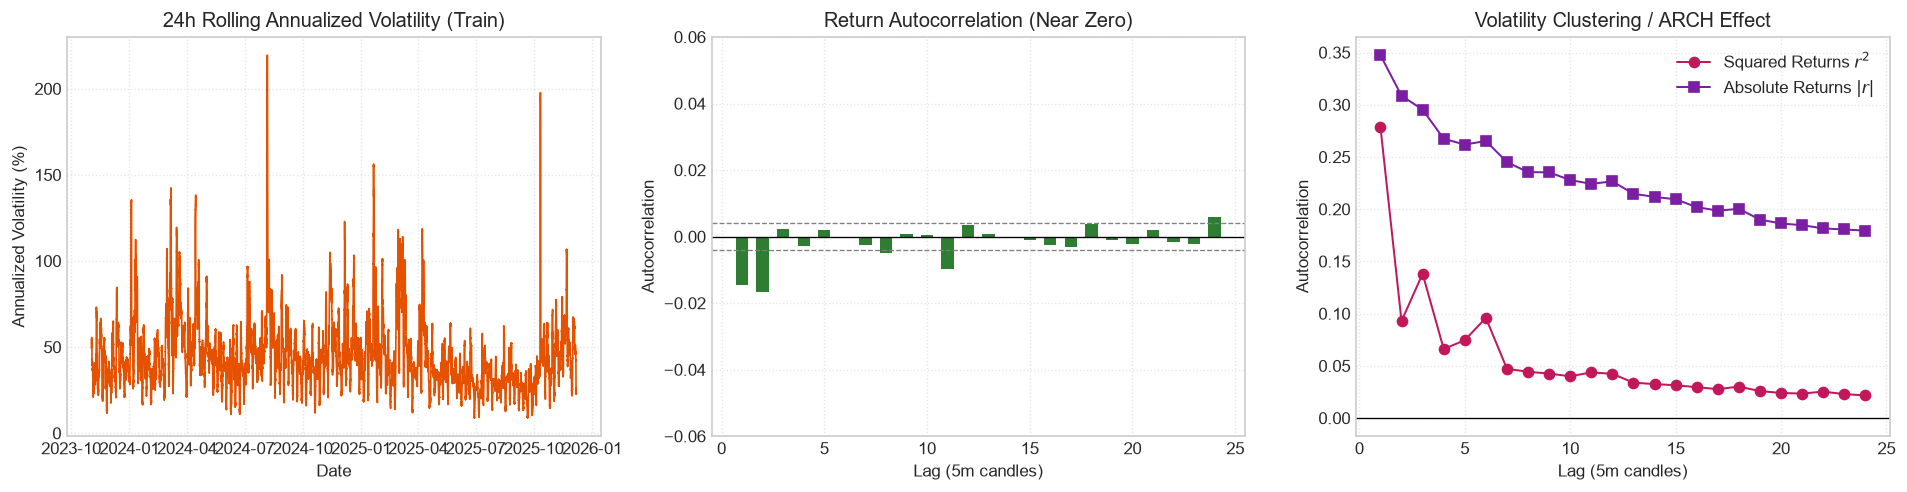

In [6]:
# 5. Volatility Over Time & Autocorrelation Functions (Returns vs Volatility)
fig_vol_acf = plot_volatility_and_acf(
    ret_5m,
    save_path=config.FIGURES_DIR / '01_train_volatility_and_acf.png'
)
plt.show()

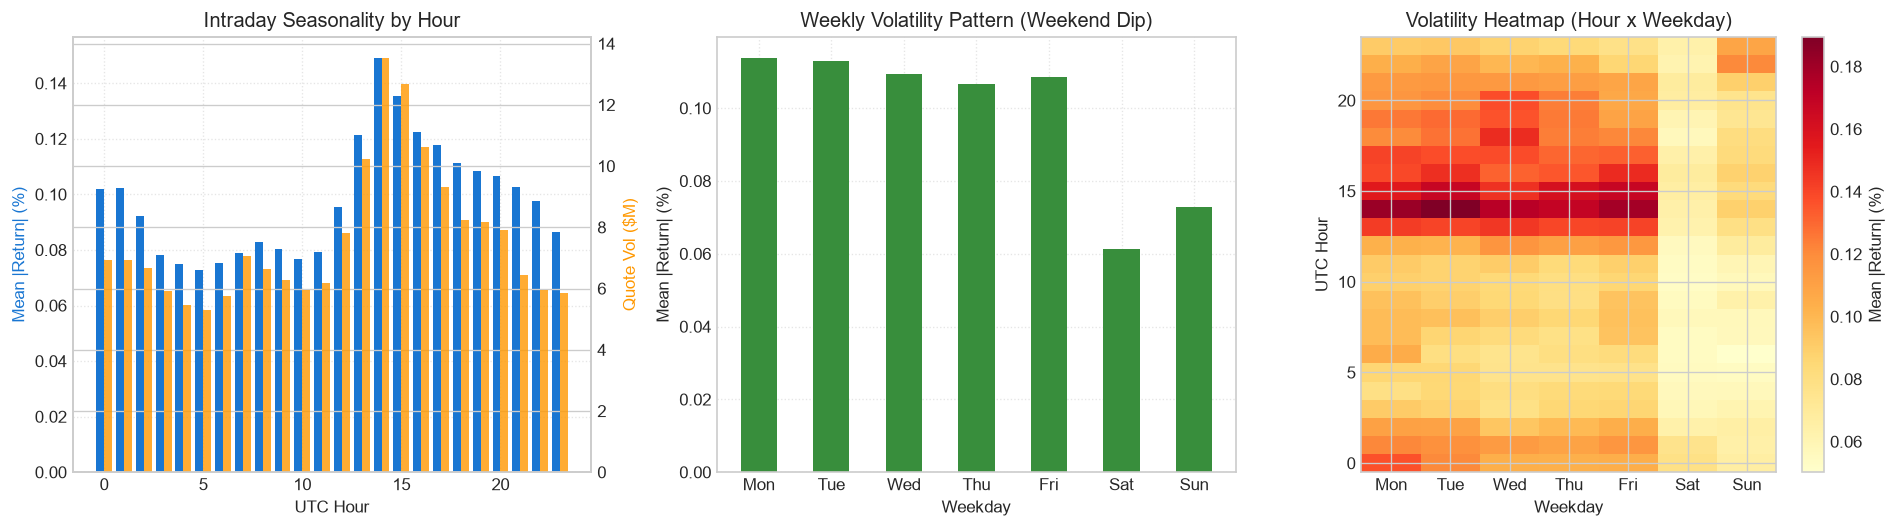

In [7]:
# 6. Diurnal and Calendar Seasonality Patterns
fig_time = plot_time_patterns(
    df_train,
    ret_5m,
    save_path=config.FIGURES_DIR / '01_train_time_patterns.png'
)
plt.show()

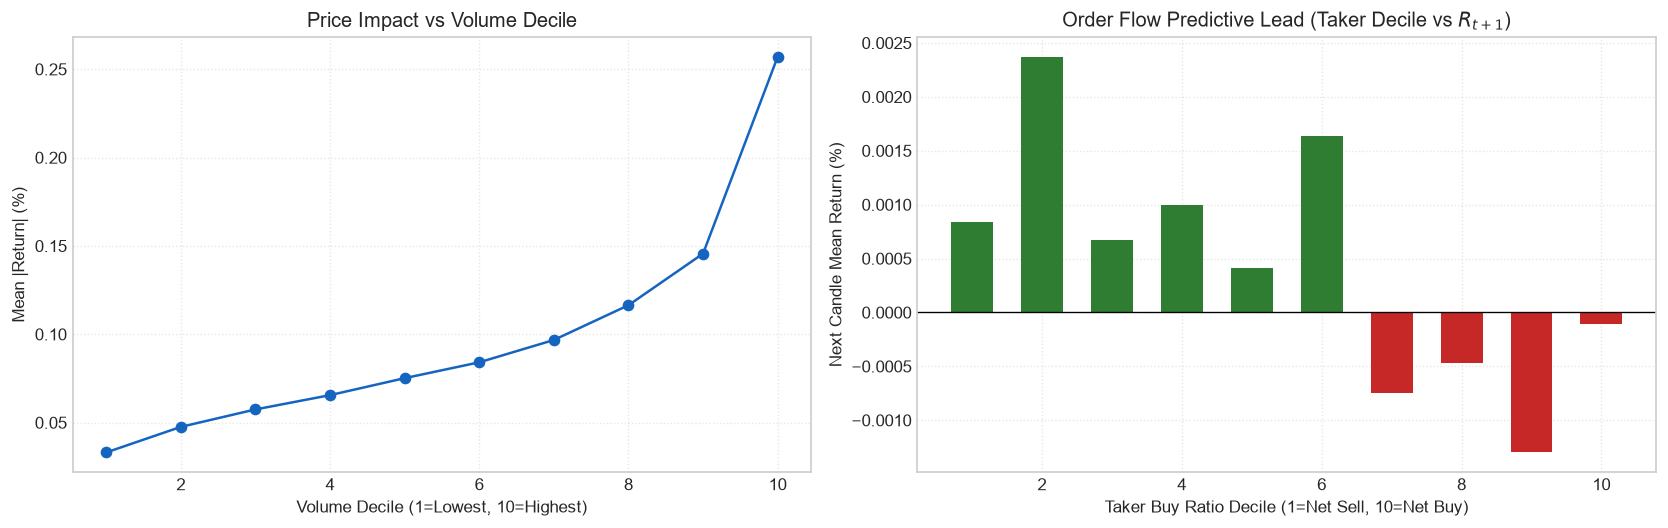

In [8]:
# 7. Market Microstructure: Volume vs |Return| and Taker Buy Ratio Lead
fig_micro = plot_microstructure_relationships(
    df_train,
    ret_5m,
    save_path=config.FIGURES_DIR / '01_train_microstructure.png'
)
plt.show()

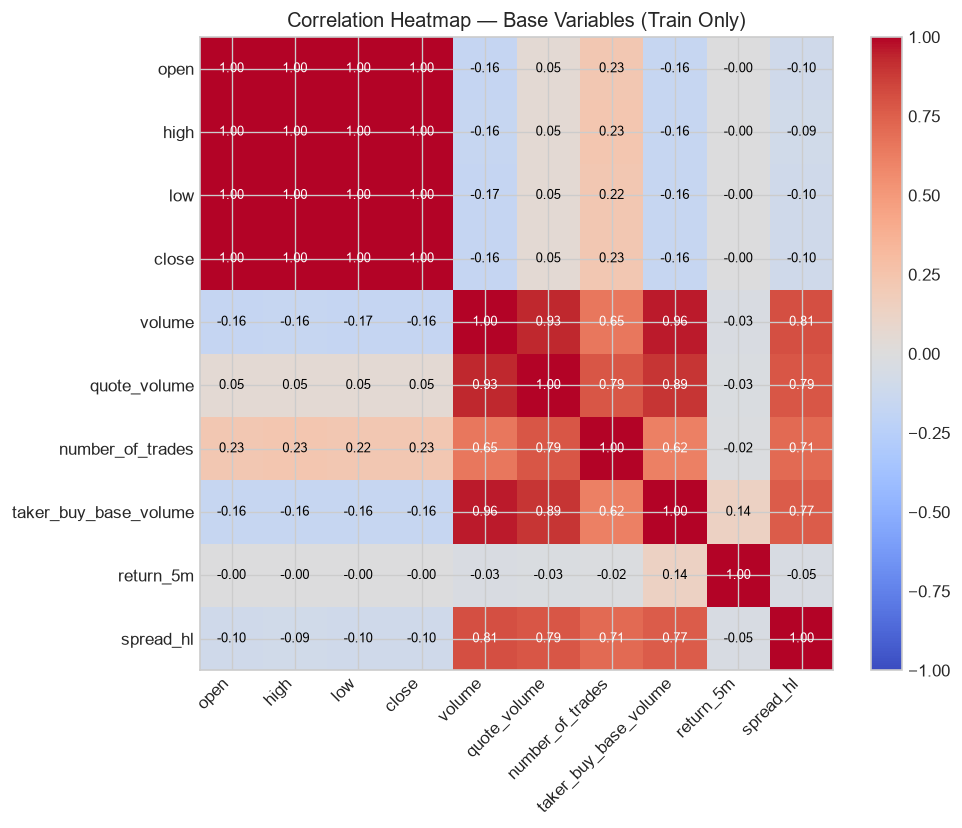

In [9]:
# 8. Correlation Heatmap (Base Variables on Train Only)
fig_corr = plot_correlation_heatmap(
    df_train,
    save_path=config.FIGURES_DIR / '01_train_correlation_heatmap.png'
)
plt.show()

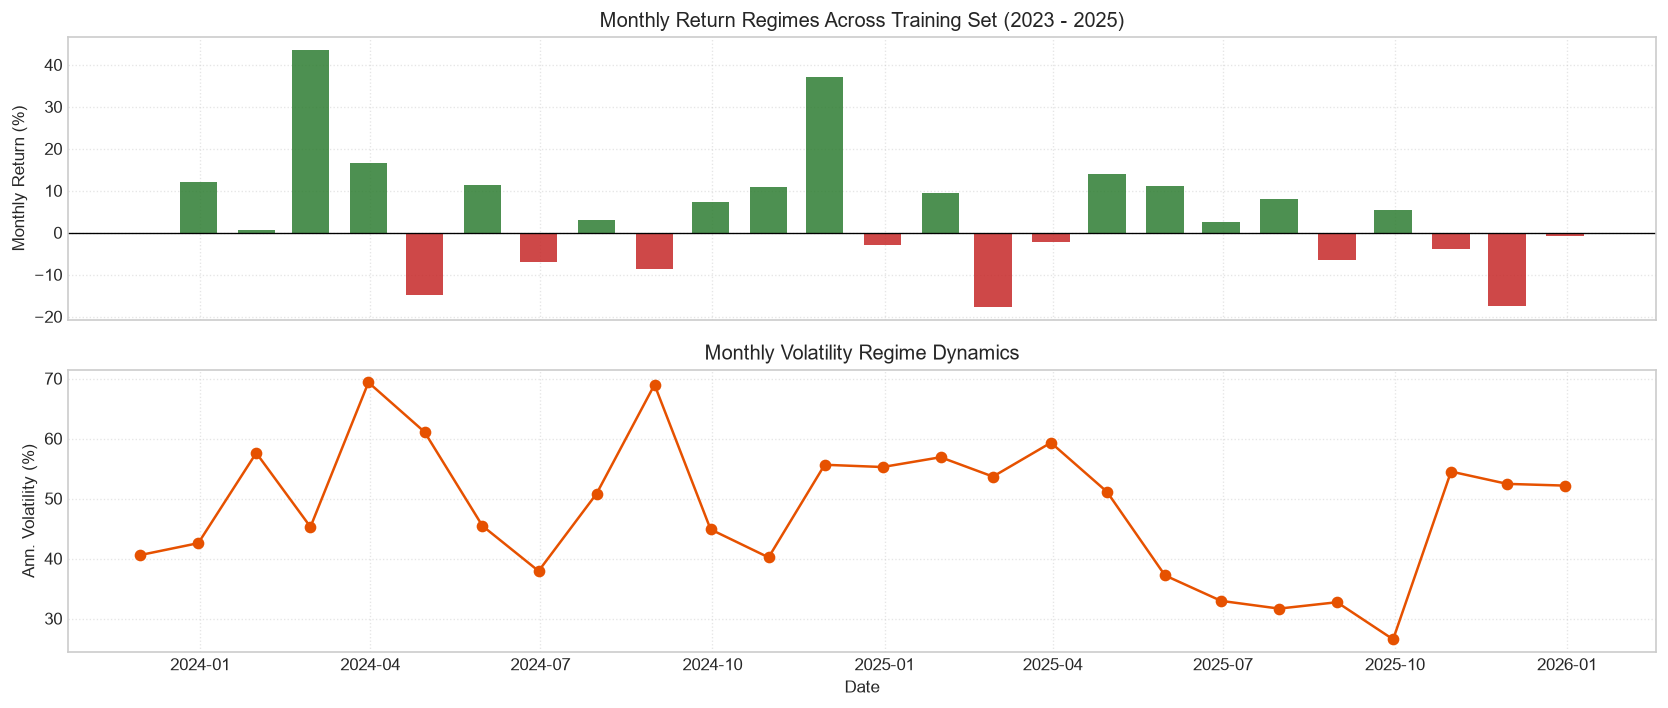

In [10]:
# 9. Monthly Return and Volatility Regimes Across Training Set
fig_regimes = plot_regimes_monthly(
    df_train,
    ret_5m,
    save_path=config.FIGURES_DIR / '01_train_regimes_monthly.png'
)
plt.show()

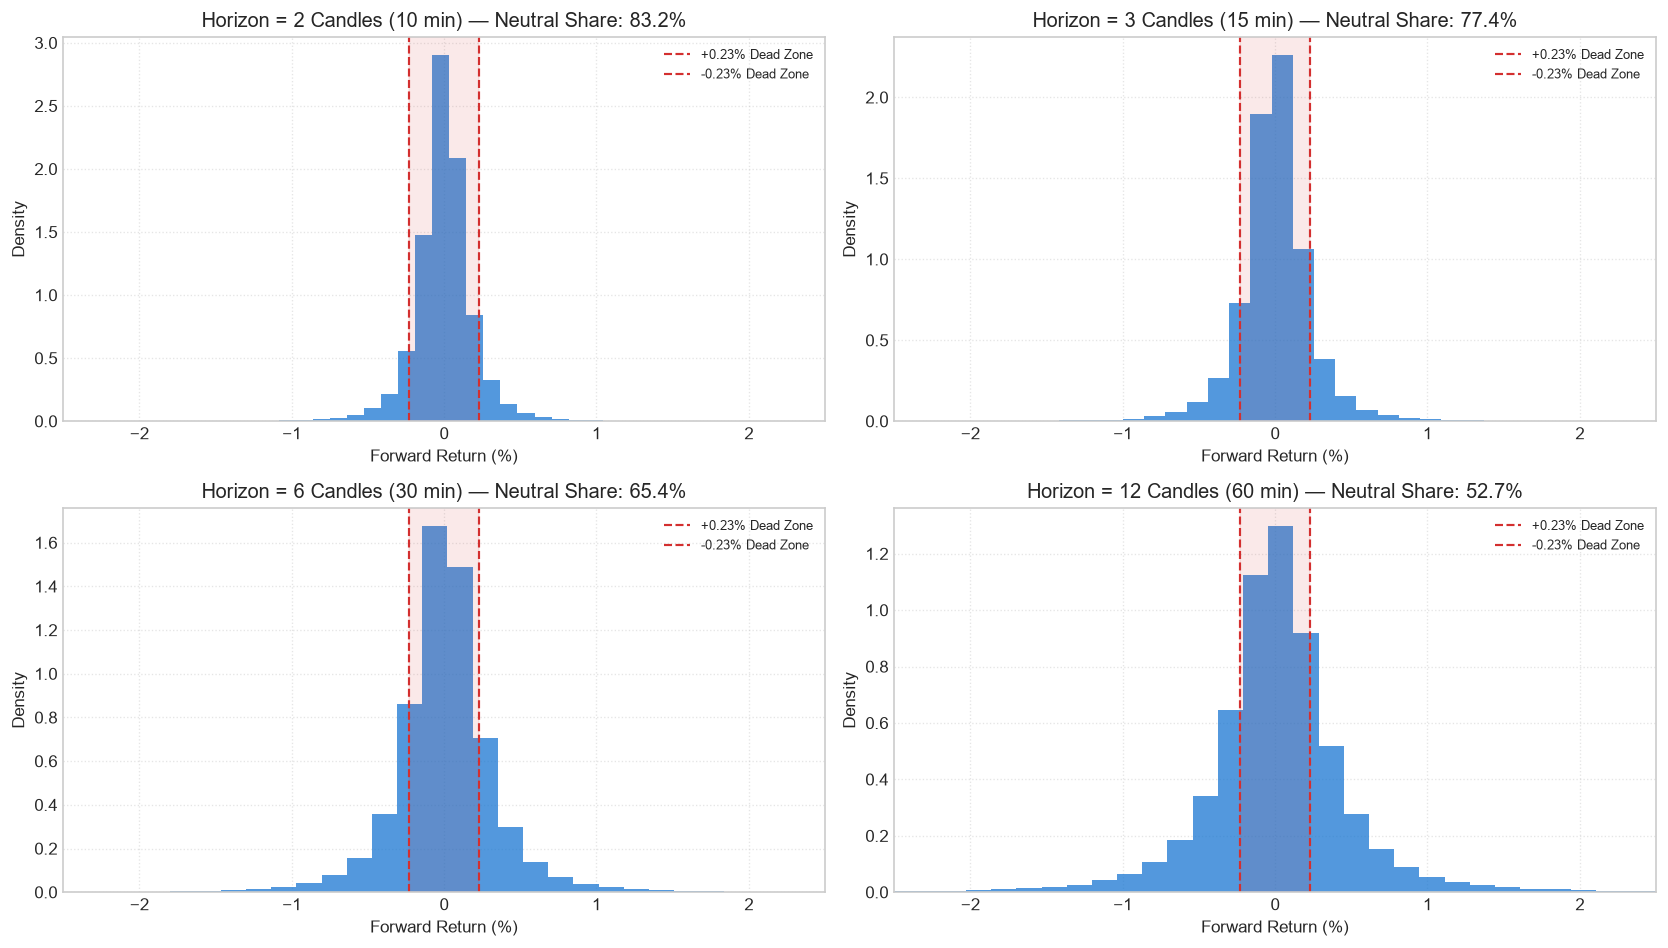

=== Candidate Horizon Dead Zone Sensitivity Table ===


,Horizon (candles),Horizon (min),Dead Zone (%),Neutral Share (%),Up Share (%),Down Share (%)
0,2,10,0.10,53.15,23.76,23.09
1,2,10,0.20,78.91,10.72,10.37
2,2,10,0.23,83.20,8.57,8.22
3,2,10,0.30,89.74,5.19,5.07
4,3,15,0.10,45.86,27.44,26.70
5,3,15,0.20,72.50,13.98,13.52
6,3,15,0.23,77.36,11.51,11.13
7,3,15,0.30,85.23,7.50,7.27
8,6,30,0.10,34.88,33.05,32.07
9,6,30,0.20,59.96,20.45,19.59


In [11]:
# 10. Forward-Return Distribution for Candidate Horizons (2, 3, 6, 12 candles)
fig_horizons = plot_forward_return_horizons(
    df_train,
    horizons=[2, 3, 6, 12],
    dead_zone=config.LABEL_DEAD_ZONE,
    save_path=config.FIGURES_DIR / '01_forward_return_horizons.png'
)
plt.show()

# Dead Zone Neutral Share Sensitivity Table for All Candidate Horizons
hz_records = []
close_arr = df_train['close'].to_numpy()
for h in [2, 3, 6, 12]:
    fwd = (close_arr[h:] / close_arr[:-h]) - 1.0
    for dz in [0.0010, 0.0020, 0.0023, 0.0030]:
        neu = (np.abs(fwd) <= dz).mean() * 100.0
        up = (fwd > dz).mean() * 100.0
        down = (fwd < -dz).mean() * 100.0
        hz_records.append({
            'Horizon (candles)': h,
            'Horizon (min)': h * 5,
            'Dead Zone (%)': round(dz * 100, 3),
            'Neutral Share (%)': round(neu, 2),
            'Up Share (%)': round(up, 2),
            'Down Share (%)': round(down, 2),
        })

hz_df = pd.DataFrame(hz_records)
print('=== Candidate Horizon Dead Zone Sensitivity Table ===')
display(hz_df)

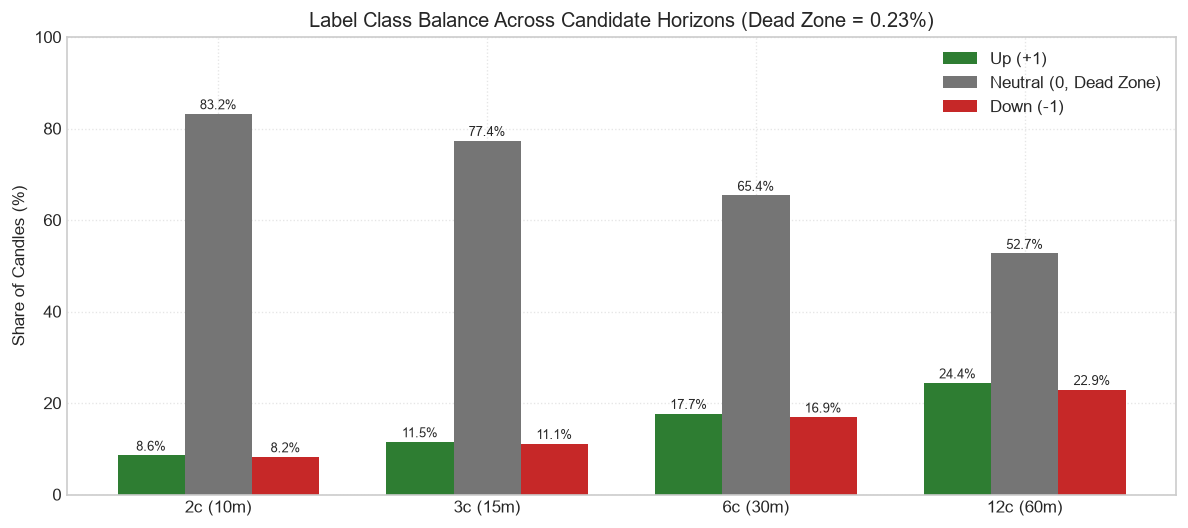

In [12]:
# 11. Label Balance Bar Charts Across Candidate Horizons
fig_bars = plot_label_balance_bars(
    df_train,
    horizons=[2, 3, 6, 12],
    dead_zone=config.LABEL_DEAD_ZONE,
    save_path=config.FIGURES_DIR / '01_label_balance_horizons.png'
)
plt.show()

## 12. Decisions and Quantitative Findings from EDA

Based on the empirical evidence gathered strictly from the Training split:

1. **Return Autocorrelation is Near Zero:**
   - Autocorrelation of raw 5-minute returns is below 0.01 across all lags up to lag 24. This confirms weak-form market efficiency; naive linear autoregression on price will fail. Alpha models must exploit non-linear combinations of order flow, momentum, and volatility clustering.

2. **Strong Volatility Clustering (ARCH Effect):**
   - Squared and absolute return autocorrelations remain statistically positive and persistent beyond lag 24. High-volatility candles cluster in time. Therefore, rolling volatility and normalized ATR features are strong conditioning variables.

3. **Pronounced Fat Tails (Kurtosis > 20):**
   - The return distribution exhibits extreme excess kurtosis (>20) and thick power-law tails that deviate severely from a Gaussian bell curve. Models with Gaussian error assumptions (standard OLS) are unsuitable; tree ensembles (LightGBM) with robust rank-based splits or regularized logistic regression are required.

4. **Intraday and Weekly Seasonality:**
   - Both trading volume and volatility surge during the US/EU trading session overlap (13:00 to 17:00 UTC) and drop during weekend intervals. Cyclical sine/cosine hour and weekday encodings are justified to capture these regular diurnal regimes.

5. **Order Flow Predictive Lead:**
   - Taker buy volume ratio deciles exhibit a positive monotonic relationship with forward returns: high net taker buying precedes upward price continuation. Order flow imbalance is a vital feature category.

6. **Dead Zone and Horizon Trade-Off:**
   - At `HORIZON = 12` (1 hour) with `LABEL_DEAD_ZONE = 0.23%`, 52.69% of candles fall inside the dead zone, leaving 104,535 tradeable samples (53,872 Up vs 50,663 Down). Shortening the horizon to 2 or 3 candles causes the neutral share to spike to 83% - 88%, rendering short horizons untradeable under spot fees. The 12-candle horizon provides the best balance between signal frequency and economic viability.